# Wet AMD Lesion Segmentation: Baseline Replication & Modern Architectures
**Dataset:** AMD-SD (Optical Coherence Tomography Image Dataset for wet AMD Lesions Segmentation)
**Objective:** Construct an automated computer vision pipeline to replicate the baseline U-Net model and establish benchmark evaluation metrics (Dice Similarity Coefficient & IoU) across 5 retinal lesion targets.

---

## 1. Project Initialization & Dataset Slicing

### Overview
In the raw AMD-SD dataset, each image file (e.g., `129_1.png`) is a composite image with a resolution of $1140 \times 380$ pixels:
* **Left Half ($570 \times 380$):** Raw optical coherence tomography (OCT) B-scan.
* **Right Half ($570 \times 380$):** Multi-class expert ground truth segmentation mask.

The dataset contains:
* **Training set:** 2,346 images listed in `training.txt`.
* **Validation set:** 703 images listed in `validation.txt`.
* **Folder structure:** Organized inside subfolders `1` to `156` by Eye ID.

This step reads the official splits, extracts each scan from its corresponding Eye ID folder, slices the composite image at the horizontal midpoint ($W // 2 = 570$), and saves separate input and output pairs into structured directories:

In [1]:
import os
import cv2
from tqdm.notebook import tqdm

# Set base paths (adjust if your notebook is located in a different folder)
BASE_DIR = "."
IMAGES_DIR = os.path.join(BASE_DIR, "images")
PROCESSED_DIR = os.path.join(BASE_DIR, "processed_data")

# Splits to process: (split_file, split_folder_name)
SPLITS = [
    ("training.txt", "train"),
    ("validation.txt", "val")
]

def slice_and_organize_dataset():
    """
    Parses training.txt and validation.txt, slices each 1140x380 composite image
    down the center, and saves separate input scans and ground truth masks.
    """
    total_processed = 0

    for split_file, split_name in SPLITS:
        split_path = os.path.join(BASE_DIR, split_file)

        if not os.path.exists(split_path):
            raise FileNotFoundError(f"Split file not found: {split_path}")

        # Destination directories
        inputs_dir = os.path.join(PROCESSED_DIR, split_name, "inputs")
        outputs_dir = os.path.join(PROCESSED_DIR, split_name, "outputs")
        os.makedirs(inputs_dir, exist_ok=True)
        os.makedirs(outputs_dir, exist_ok=True)

        with open(split_path, "r") as f:
            file_list = [line.strip() for line in f if line.strip()]

        print(f"\nProcessing {split_name.upper()} split ({len(file_list)} files)...")

        for filename in tqdm(file_list, desc=f"Slicing {split_name}"):
            # Parse Eye ID subfolder from filename (e.g., '129_1.png' -> folder '129')
            eye_folder = filename.split("_")[0]
            src_file = os.path.join(IMAGES_DIR, eye_folder, filename)

            if not os.path.exists(src_file):
                print(f"Warning: File missing: {src_file}")
                continue

            img = cv2.imread(src_file)
            if img is None:
                print(f"Error reading image: {src_file}")
                continue

            h, w, _ = img.shape
            midpoint = w // 2  # Horizontal center (570 px)

            # Left: raw OCT scan | Right: ground truth mask
            input_scan = img[:, :midpoint]
            output_mask = img[:, midpoint:]

            # Save decoupled images with uniform naming
            base_name = os.path.splitext(filename)[0]
            cv2.imwrite(os.path.join(inputs_dir, f"{base_name}_input.png"), input_scan)
            cv2.imwrite(os.path.join(outputs_dir, f"{base_name}_output.png"), output_mask)
            total_processed += 1

    print(f"\nSlicing complete. Successfully processed {total_processed} image pairs.")

# Execute dataset slicing
slice_and_organize_dataset()


Processing TRAIN split (2346 files)...


Slicing train:   0%|          | 0/2346 [00:00<?, ?it/s]

KeyboardInterrupt: 

### 1.1 Dataset Verification
Verify that all 2,346 training pairs and 703 validation pairs were successfully extracted and saved.

In [2]:
train_in_count = len(os.listdir(os.path.join(PROCESSED_DIR, "train", "inputs")))
train_out_count = len(os.listdir(os.path.join(PROCESSED_DIR, "train", "outputs")))
val_in_count = len(os.listdir(os.path.join(PROCESSED_DIR, "val", "inputs")))
val_out_count = len(os.listdir(os.path.join(PROCESSED_DIR, "val", "outputs")))

print(f"Training Inputs:     {train_in_count:4d} / 2346 expected")
print(f"Training Outputs:    {train_out_count:4d} / 2346 expected")
print(f"Validation Inputs:   {val_in_count:4d} /  703 expected")
print(f"Validation Outputs:  {val_out_count:4d} /  703 expected")

assert train_in_count == 2346 and train_out_count == 2346, "Training count mismatch!"
assert val_in_count == 703 and val_out_count == 703, "Validation count mismatch!"
print("\nAll files sliced and verified successfully!")

Training Inputs:     2346 / 2346 expected
Training Outputs:    2346 / 2346 expected
Validation Inputs:    703 /  703 expected
Validation Outputs:   703 /  703 expected

All files sliced and verified successfully!


## 2. PyTorch Dataset Pipeline & Color-to-Class Encoding

### Overview & Methodology
Neural network segmentation targets must be integer class tensors of shape $(H, W)$ where each pixel value corresponds to a specific class ID ($0$ to $5$)[cite: 5]. The sliced ground truth masks are 3-channel RGB images[cite: 5]. 

This step defines a custom PyTorch `Dataset` that implements:
1. **Filename Pairing:** Reliably pairs each sliced scan (`_input.png`) with its ground truth mask (`_output.png`)[cite: 6].
2. **Dimension Resizing ($384 \times 576$):** 
   * The original sliced resolution is $570 \times 380$ (Width $\times$ Height, aspect ratio $= 1.5$)[cite: 5, 6].
   * A 4-stage U-Net downsamples feature maps four times ($2^4 = 16$ or $2^5 = 32$). Both height $384$ ($32 \times 12$) and width $576$ ($32 \times 18$) are divisible by 32 while preserving the exact $1.5$ aspect ratio, preventing spatial dimension mismatch errors during skip connection concatenation.
3. **Nearest-Neighbor Interpolation for Masks:** Resizing masks with linear interpolation introduces blended, non-existent boundary colors. Using `cv2.INTER_NEAREST` preserves true class boundaries.
4. **Color Centroid Quantization:** Computes squared Euclidean distance between each unique pixel color and the 6 target class centroids in RGB space, mapping every pixel to its integer label ID[cite: 5]:
   * **Class 0:** Background `[0, 0, 0]` (Black)[cite: 5]
   * **Class 1:** Subretinal Fluid (SRF) `[255, 0, 0]` (Red)[cite: 5]
   * **Class 2:** Intraretinal Fluid (IRF) `[0, 255, 0]` (Green)[cite: 5]
   * **Class 3:** Pigment Epithelial Detachment (PED) `[0, 0, 255]` (Blue)[cite: 5]
   * **Class 4:** Subretinal Hyperreflective Material (SHRM) `[255, 255, 0]` (Yellow)[cite: 5]
   * **Class 5:** Ellipsoid Zone (IS/OS) `[255, 0, 255]` (Pink)[cite: 5]
5. **Tensor Conversion:** Normalizes raw OCT scans to $[0.0, 1.0]$ with shape `(1, H, W)` (`torch.float32`) and masks to shape `(H, W)` (`torch.int64` / `LongTensor`).

In [3]:
import os
import cv2
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader

# Reference RGB color palette for the 6 target classes
CLASS_PALETTE_RGB = np.array([
    [0, 0, 0],        # 0: Background
    [255, 0, 0],      # 1: Subretinal Fluid (SRF)
    [0, 255, 0],      # 2: Intraretinal Fluid (IRF)
    [0, 0, 255],      # 3: Pigment Epithelial Detachment (PED)
    [255, 255, 0],    # 4: Subretinal Hyperreflective Material (SHRM)
    [255, 0, 255]     # 5: Ellipsoid Zone (IS/OS)
], dtype=np.int32)

CLASS_NAMES = ["Background", "SRF", "IRF", "PED", "SHRM", "IS/OS"]

class AMDDataset(Dataset):
    def __init__(self, data_root, split="train", target_size=(384, 576)):
        """
        Args:
            data_root: Path containing the 'processed_data' directory.
            split: 'train' or 'val'.
            target_size: Tuple (Height, Width) divisible by 32.
        """
        self.inputs_dir = os.path.join(data_root, split, "inputs")
        self.outputs_dir = os.path.join(data_root, split, "outputs")
        self.target_size = target_size

        # Load valid image filenames, ignoring OS metadata (e.g., .DS_Store)
        self.filenames = sorted([
            f for f in os.listdir(self.inputs_dir)
            if f.endswith(('.png', '.jpg', '.jpeg')) and not f.startswith('.')
        ])

    def __len__(self):
        return len(self.filenames)

    def _rgb_to_class(self, mask_rgb):
        """
        Maps a 3-channel RGB mask to a 2D integer class map (0 to 5) 
        using vectorized Euclidean distance to centroid colors.
        """
        # Ensure contiguous numeric array
        mask = np.ascontiguousarray(mask_rgb, dtype=np.int32)

        # Broadcasted distance: (H, W, 1, 3) - (1, 1, 6, 3) -> (H, W, 6)
        dists = np.sum((mask[:, :, None, :] - CLASS_PALETTE_RGB[None, None, :, :]) ** 2, axis=-1)

        # Nearest centroid class per pixel
        return np.argmin(dists, axis=-1)

    def __getitem__(self, idx):
        in_fname = self.filenames[idx]
        img_path = os.path.join(self.inputs_dir, in_fname)

        # Match corresponding mask filename
        out_fname = in_fname.replace("_input", "_output") if "_input" in in_fname else in_fname
        mask_path = os.path.join(self.outputs_dir, out_fname)

        if not os.path.exists(img_path):
            raise FileNotFoundError(f"Input image missing: {img_path}")
        if not os.path.exists(mask_path):
            raise FileNotFoundError(f"Output mask missing: {mask_path}")

        # 1. Load input OCT scan (grayscale) and mask (RGB)
        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        mask_bgr = cv2.imread(mask_path)
        
        if img is None:
            raise ValueError(f"Failed to read image at: {img_path}")
        if mask_bgr is None:
            raise ValueError(f"Failed to read mask at: {mask_path}")
            
        mask_rgb = cv2.cvtColor(mask_bgr, cv2.COLOR_BGR2RGB)

        # 2. Resize: bilinear for input scan, nearest-neighbor for mask labels
        img = cv2.resize(img, (self.target_size[1], self.target_size[0]), interpolation=cv2.INTER_LINEAR)
        mask_rgb = cv2.resize(mask_rgb, (self.target_size[1], self.target_size[0]), interpolation=cv2.INTER_NEAREST)

        # 3. Convert RGB mask to 2D integer class map
        mask_labels = self._rgb_to_class(mask_rgb)

        # 4. Convert to PyTorch tensors
        img_tensor = torch.from_numpy(np.ascontiguousarray(img)).unsqueeze(0).float() / 255.0  # Shape: (1, H, W)
        mask_tensor = torch.from_numpy(np.ascontiguousarray(mask_labels)).long()               # Shape: (H, W)

        return img_tensor, mask_tensor

### 2.1 DataLoader Setup & Visual Batch Inspection
Instantiate training and validation `DataLoader` instances and visualize an input scan alongside its encoded categorical mask to confirm correct label alignment.

In [4]:
import os
import cv2
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader

# Reference RGB color palette for the 6 target classes
CLASS_PALETTE_RGB = np.array([
    [0, 0, 0],        # 0: Background
    [255, 0, 0],      # 1: Subretinal Fluid (SRF)
    [0, 255, 0],      # 2: Intraretinal Fluid (IRF)
    [0, 0, 255],      # 3: Pigment Epithelial Detachment (PED)
    [255, 255, 0],    # 4: Subretinal Hyperreflective Material (SHRM)
    [255, 0, 255]     # 5: Ellipsoid Zone (IS/OS)
], dtype=np.int32)

CLASS_NAMES = ["Background", "SRF", "IRF", "PED", "SHRM", "IS/OS"]

class AMDDataset(Dataset):
    def __init__(self, data_root, split="train", target_size=(384, 576)):
        self.inputs_dir = os.path.join(data_root, split, "inputs")
        self.outputs_dir = os.path.join(data_root, split, "outputs")
        self.target_size = target_size

        self.filenames = sorted([
            f for f in os.listdir(self.inputs_dir)
            if f.endswith(('.png', '.jpg', '.jpeg')) and not f.startswith('.')
        ])

    def __len__(self):
        return len(self.filenames)

    def _rgb_to_class(self, mask_rgb):
        mask = np.ascontiguousarray(mask_rgb, dtype=np.int32)
        dists = np.sum((mask[:, :, None, :] - CLASS_PALETTE_RGB[None, None, :, :]) ** 2, axis=-1)
        return np.argmin(dists, axis=-1)

    def __getitem__(self, idx):
        in_fname = self.filenames[idx]
        img_path = os.path.join(self.inputs_dir, in_fname)

        out_fname = in_fname.replace("_input", "_output") if "_input" in in_fname else in_fname
        mask_path = os.path.join(self.outputs_dir, out_fname)

        if not os.path.exists(img_path):
            raise FileNotFoundError(f"Input image missing: {img_path}")
        if not os.path.exists(mask_path):
            raise FileNotFoundError(f"Output mask missing: {mask_path}")

        # 1. Load input OCT scan (grayscale) and mask (RGB)
        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        mask_bgr = cv2.imread(mask_path)
        
        if img is None:
            raise ValueError(f"Failed to read image at: {img_path}")
        if mask_bgr is None:
            raise ValueError(f"Failed to read mask at: {mask_path}")

        mask_rgb = cv2.cvtColor(mask_bgr, cv2.COLOR_BGR2RGB)

        # 2. Resize: bilinear for input scan, nearest-neighbor for mask labels
        img = cv2.resize(img, (self.target_size[1], self.target_size[0]), interpolation=cv2.INTER_LINEAR)
        mask_rgb = cv2.resize(mask_rgb, (self.target_size[1], self.target_size[0]), interpolation=cv2.INTER_NEAREST)

        # 3. Convert RGB mask to 2D integer class map
        mask_labels = self._rgb_to_class(mask_rgb)

        # 4. Convert to PyTorch tensors using DLPack (bypasses NumPy C-API type mismatch)
        img_arr = np.ascontiguousarray(img, dtype=np.float32) / 255.0
        mask_arr = np.ascontiguousarray(mask_labels, dtype=np.int64)

        img_tensor = torch.from_dlpack(img_arr).unsqueeze(0)  # Shape: (1, H, W)
        mask_tensor = torch.from_dlpack(mask_arr)              # Shape: (H, W)

        return img_tensor, mask_tensor

## 3. Baseline U-Net Architecture Implementation

### Overview & Architectural Design
This module defines the exact U-Net baseline designed for multi-class retinal OCT lesion segmentation[cite: 5]. The network utilizes a symmetric encoder-decoder topology with skip connections to simultaneously extract deep context and preserve fine spatial boundaries[cite: 5]:

1. **DoubleConv Blocks:** Each stage applies two successive $3 \times 3$ convolutions with `padding=1`, Batch Normalization, and ReLU activations.
2. **Encoder (Contracting Path):** Sequentially downsamples feature maps using $2 \times 2$ Max-Pooling (`stride=2`), doubling channel depth at each hierarchy ($32 \to 64 \to 128 \to 256$)[cite: 5].
3. **Bottleneck:** Deepest representations are processed at a depth of $512$ channels ($c \times 16$).
4. **Dynamic Feature Concatenation (`_match_and_cat`):** Calculates spatial differences between upsampled decoder tensors and encoder skip connections, applying dynamic reflection/zero padding if non-standard or odd spatial resolutions occur.
5. **Decoder (Expanding Path):** Restores spatial dimensions via $2 \times 2$ Transposed Convolutions (`stride=2`), concatenates matching encoder skip connections, and processes features through `DoubleConv` blocks.
6. **Segmentation Head:** A final $1 \times 1$ convolution projects 32 features into 6 logit channels representing background and the 5 wet AMD lesion categories[cite: 5].

In [5]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class DoubleConv(nn.Module):
    """[Conv2d -> BatchNorm -> ReLU] * 2"""
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.block(x)


class UNet(nn.Module):
    def __init__(self, in_channels: int = 1, num_classes: int = 6, base_channels: int = 32):
        """
        Customizable U-Net baseline for medical scan segmentation[cite: 5].
        
        Args:
            in_channels: Input channels (1 for grayscale OCT B-scans).
            num_classes: Number of output prediction classes (background + 5 AMD lesions)[cite: 5].
            base_channels: Starting feature depth (default 32 -> 64 -> 128 -> 256 -> 512).
        """
        super().__init__()
        c = base_channels
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Encoder (Contracting Path)
        self.inc = DoubleConv(in_channels, c)               # 1 -> 32
        self.down1 = DoubleConv(c, c * 2)                  # 32 -> 64
        self.down2 = DoubleConv(c * 2, c * 4)              # 64 -> 128
        self.down3 = DoubleConv(c * 4, c * 8)              # 128 -> 256

        # Bottleneck
        self.bottleneck = DoubleConv(c * 8, c * 16)        # 256 -> 512

        # Decoder (Expanding Path)
        self.up1 = nn.ConvTranspose2d(c * 16, c * 8, kernel_size=2, stride=2)
        self.conv_up1 = DoubleConv(c * 16, c * 8)          # (256 skip + 256 up) -> 256

        self.up2 = nn.ConvTranspose2d(c * 8, c * 4, kernel_size=2, stride=2)
        self.conv_up2 = DoubleConv(c * 8, c * 4)           # (128 skip + 128 up) -> 128

        self.up3 = nn.ConvTranspose2d(c * 4, c * 2, kernel_size=2, stride=2)
        self.conv_up3 = DoubleConv(c * 4, c * 2)           # (64 skip + 64 up) -> 64

        self.up4 = nn.ConvTranspose2d(c * 2, c, kernel_size=2, stride=2)
        self.conv_up4 = DoubleConv(c * 2, c)               # (32 skip + 32 up) -> 32

        # Final Classifier Head
        self.outc = nn.Conv2d(c, num_classes, kernel_size=1)

    def _match_and_cat(self, x_up: torch.Tensor, x_skip: torch.Tensor) -> torch.Tensor:
        """Pads x_up dynamically if tensor dimensions differ due to odd input shapes."""
        if x_up.shape[2:] != x_skip.shape[2:]:
            diff_y = x_skip.size(2) - x_up.size(2)
            diff_x = x_skip.size(3) - x_up.size(3)
            x_up = F.pad(x_up, [diff_x // 2, diff_x - diff_x // 2,
                               diff_y // 2, diff_y - diff_y // 2])
        return torch.cat([x_skip, x_up], dim=1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Encoder
        x1 = self.inc(x)
        x2 = self.down1(self.pool(x1))
        x3 = self.down2(self.pool(x2))
        x4 = self.down3(self.pool(x3))

        # Bottleneck
        m = self.bottleneck(self.pool(x4))

        # Decoder + Skip Connections
        d1 = self._match_and_cat(self.up1(m), x4)
        d1 = self.conv_up1(d1)

        d2 = self._match_and_cat(self.up2(d1), x3)
        d2 = self.conv_up2(d2)

        d3 = self._match_and_cat(self.up3(d2), x2)
        d3 = self.conv_up3(d3)

        d4 = self._match_and_cat(self.up4(d3), x1)
        d4 = self.conv_up4(d4)

        return self.outc(d4)  # Outputs raw logits [B, 6, H, W]

### 3.1 Model Architecture Sanity Test & Parameter Count
Instantiate the U-Net with a synthetic batch matching your OCT input dimensions (`[Batch=2, Channels=1, Height=384, Width=576]`) to verify forward-pass stability, skip concatenation, and total trainable parameter count.

In [6]:
# Instantiate baseline model
device = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
model = UNet(in_channels=1, num_classes=6, base_channels=32).to(device)

# Synthetic test batch matching resized resolution
dummy_input = torch.randn(2, 1, 384, 576, device=device)
with torch.no_grad():
    dummy_output = model(dummy_input)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Device utilized:              {device}")
print(f"Input batch tensor shape:     {tuple(dummy_input.shape)}")
print(f"Output logits tensor shape:   {tuple(dummy_output.shape)} (Expected: [2, 6, 384, 576])")
print(f"Total trainable parameters:   {total_params:,}")
assert dummy_output.shape == (2, 6, 384, 576), "Output shape mismatch!"
print("\nU-Net architecture verified successfully!")

Device utilized:              mps
Input batch tensor shape:     (2, 1, 384, 576)
Output logits tensor shape:   (2, 6, 384, 576) (Expected: [2, 6, 384, 576])
Total trainable parameters:   7,762,630

U-Net architecture verified successfully!


## 4. Loss Function & Clinical Evaluation Metrics

### Overview & Formulation
Retinal lesions represent a small fraction of the total area of an optical coherence tomography (OCT) B-scan, with the majority of pixels occupied by background tissue[cite: 5]. Relying solely on standard Cross-Entropy loss causes the optimization process to bias heavily toward background classification.

This module establishes a hybrid loss and evaluation framework[cite: 5]:
1. **Cross-Entropy Loss ($\mathcal{L}_{CE}$):** Evaluates overall pixel-wise classification probabilities across all classes:
   $$\mathcal{L}_{CE} = -\frac{1}{N} \sum_{i=1}^N \sum_{c=0}^5 y_{i,c} \log(p_{i,c})$$
2. **Multi-Class Soft Dice Loss ($\mathcal{L}_{\text{Dice}}$):** Measures spatial overlap between model prediction probabilities and ground-truth masks. The background class ($0$) is excluded from Dice loss calculation to concentrate gradient descent on the five lesion biomarkers[cite: 5]:
   $$\mathcal{L}_{\text{Dice}} = \frac{1}{C-1} \sum_{c=1}^5 \left( 1 - \frac{2 \sum (p_c \cdot t_c) + \epsilon}{\sum p_c + \sum t_c + \epsilon} \right)$$
3. **Combined Objective:** Computes a balanced weighted combination:
   $$\mathcal{L}_{\text{Total}} = w_{ce} \cdot \mathcal{L}_{CE} + w_{dice} \cdot \mathcal{L}_{\text{Dice}}$$
4. **Clinical Evaluation Metrics (`calculate_metrics`):** Computes percentage Dice Similarity Coefficient (DSC) and Intersection over Union (IoU) per lesion class (SRF, IRF, PED, SHRM, IS/OS) to benchmark against Table 3 in the AMD-SD paper[cite: 5].

In [7]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class CombinedLoss(nn.Module):
    def __init__(self, num_classes: int = 6, ce_weight: float = 0.5, dice_weight: float = 0.5, smooth: float = 1e-5):
        """
        Hybrid loss balancing pixel-level Cross-Entropy with foreground Soft Dice loss[cite: 5].
        
        Args:
            num_classes: Total classes including background (default: 6)[cite: 5].
            ce_weight: Weight assigned to Cross-Entropy loss.
            dice_weight: Weight assigned to Multi-class Dice loss.
            smooth: Laplace smoothing constant to prevent division by zero.
        """
        super().__init__()
        self.num_classes = num_classes
        self.ce_weight = ce_weight
        self.dice_weight = dice_weight
        self.smooth = smooth
        self.ce = nn.CrossEntropyLoss()

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        # Cross-Entropy loss expects targets as [B, H, W] of class indices
        ce_loss = self.ce(logits, targets)

        # Multi-class Soft Dice Loss
        probs = F.softmax(logits, dim=1)
        targets_one_hot = F.one_hot(targets, num_classes=self.num_classes).permute(0, 3, 1, 2).float()

        dice_total = 0.0
        # Exclude background (class 0) from dice computation to optimize lesion foreground
        for c in range(1, self.num_classes):
            p = probs[:, c, ...].contiguous().view(-1)
            t = targets_one_hot[:, c, ...].contiguous().view(-1)
            intersection = (p * t).sum()
            dice = (2.0 * intersection + self.smooth) / (p.sum() + t.sum() + self.smooth)
            dice_total += (1.0 - dice)

        dice_loss = dice_total / (self.num_classes - 1)
        return (self.ce_weight * ce_loss) + (self.dice_weight * dice_loss)


def calculate_metrics(preds: torch.Tensor, targets: torch.Tensor, smooth: float = 1e-5):
    """
    Computes percentage Dice Similarity Coefficient and IoU for the 5 retinal biomarker classes[cite: 5].
    Classes: 1: SRF, 2: IRF, 3: PED, 4: SHRM, 5: IS/OS (0 is Background)[cite: 5].
    
    Args:
        preds: Tensor of predicted class indices [B, H, W].
        targets: Tensor of ground-truth class indices [B, H, W].
        smooth: Smoothing epsilon.
        
    Returns:
        dice_scores: Dictionary of per-class Dice percentages.
        iou_scores: Dictionary of per-class IoU percentages.
    """
    class_map = {
        1: "SRF",
        2: "IRF",
        3: "PED",
        4: "SHRM",
        5: "IS/OS"
    }
    dice_scores = {}
    iou_scores = {}

    for cls_idx, cls_name in class_map.items():
        p_mask = (preds == cls_idx).float()
        t_mask = (targets == cls_idx).float()

        intersection = (p_mask * t_mask).sum().item()
        total_p = p_mask.sum().item()
        total_t = t_mask.sum().item()
        union = total_p + total_t - intersection

        # Dice and IoU percentage scores
        dice = (2.0 * intersection + smooth) / (total_p + total_t + smooth) * 100.0
        iou = (intersection + smooth) / (union + smooth) * 100.0

        dice_scores[cls_name] = dice
        iou_scores[cls_name] = iou

    return dice_scores, iou_scores

### 4.1 Loss & Metrics Verification
Verify the computation of `CombinedLoss` and `calculate_metrics` using synthetic batch tensors to confirm expected numeric output ranges and dictionary mappings.

In [8]:
# Create synthetic batch: 2 samples, 6 classes, 384x576 resolution
synthetic_logits = torch.randn(2, 6, 384, 576)
synthetic_targets = torch.randint(0, 6, (2, 384, 576))

# Test loss computation
criterion = CombinedLoss(num_classes=6, ce_weight=0.5, dice_weight=0.5)
test_loss = criterion(synthetic_logits, synthetic_targets)

# Test metric computation
synthetic_preds = torch.argmax(synthetic_logits, dim=1)
dice_sample, iou_sample = calculate_metrics(synthetic_preds, synthetic_targets)

print(f"Calculated Combined Loss: {test_loss.item():.4f}")
print("\nPer-Class Dice Scores (%):")
for cls, score in dice_sample.items():
    print(f"  {cls:6s}: {score:.2f}%")

print("\nPer-Class IoU Scores (%):")
for cls, score in iou_sample.items():
    print(f"  {cls:6s}: {score:.2f}%")

assert test_loss.item() > 0, "Loss value must be strictly positive!"
print("\nLoss and metric functions verified successfully!")

Calculated Combined Loss: 1.5049

Per-Class Dice Scores (%):
  SRF   : 16.61%
  IRF   : 16.66%
  PED   : 16.52%
  SHRM  : 16.76%
  IS/OS : 16.72%

Per-Class IoU Scores (%):
  SRF   : 9.06%
  IRF   : 9.09%
  PED   : 9.01%
  SHRM  : 9.15%
  IS/OS : 9.12%

Loss and metric functions verified successfully!


## 5. Baseline U-Net Training Pipeline & Checkpointing

### Overview & Training Protocol
This module executes the supervised training loop for replicating the baseline U-Net on the AMD-SD dataset[cite: 5]:

1. **Reproducibility Seeding (`seed_everything`):** Locks Python, NumPy, and PyTorch random seeds (`seed=42`) to guarantee reproducible weight initializations and batch permutations.
2. **Device Acceleration & Multiprocessing Safety:** 
   * Auto-detects Apple Silicon (`mps`), NVIDIA GPU (`cuda`), or fallback `cpu`.
   * Sets `num_workers=0` on macOS/MPS to eliminate deadlocks between OpenCV image decoders and POSIX fork multiprocessing, while setting `num_workers=2` with `pin_memory=True` on CUDA systems.
3. **Optimization Strategy:**
   * **Optimizer:** AdamW with an initial learning rate $\eta = 1 \times 10^{-4}$ and weight decay $\lambda = 1 \times 10^{-4}$ to prevent overfitting on subtle lesions[cite: 5].
   * **Learning Rate Scheduler:** `CosineAnnealingLR` decaying over 30 epochs toward $\eta_{\min} = 1 \times 10^{-6}$, providing smooth convergence in late epochs.
4. **Validation & Checkpointing:**
   * At the end of every epoch, evaluates all 703 validation scans across the 5 target lesion classes (SRF, IRF, PED, SHRM, IS/OS)[cite: 2, 5].
   * Logs epoch training loss, validation loss, Mean Dice, Mean IoU, and per-class metrics into `training_log.csv`.
   * Automatically saves the state dictionary to `best_unet_baseline.pth` whenever validation Mean Dice reaches a new maximum.

In [10]:
import os
import csv
import random
import numpy as np
import torch
from torch.utils.data import DataLoader
from tqdm import tqdm

# Seed Utility & Worker Hook
def seed_everything(seed: int = 42):
    """Locks random seeds across libraries and backends."""
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

def seed_worker(worker_id):
    """Ensures each DataLoader worker sub-process inherits deterministic seeds."""
    worker_seed = torch.initial_seed() % (2**32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)

# Main Training Routine
def run_training():
    SEED = 42
    seed_everything(SEED)

    # Dedicated PyTorch generator for DataLoader batch shuffling
    g = torch.Generator()
    g.manual_seed(SEED)

    # 1. Detect hardware acceleration
    if torch.backends.mps.is_available():
        device = torch.device("mps")
    elif torch.cuda.is_available():
        device = torch.device("cuda")
    else:
        device = torch.device("cpu")
    print(f"Active Compute Device: {device}")

    # 2. Hyperparameters
    DATA_DIR = "processed_data"
    BATCH_SIZE = 4
    NUM_WORKERS = 2 if device.type == "cuda" else 0  # Avoids OpenCV thread locks on macOS
    EPOCHS = 40
    LEARNING_RATE = 1e-4
    NUM_CLASSES = 6
    LOG_FILE = "training_log.csv"

    # 3. Datasets and Loaders
    train_dataset = AMDDataset(DATA_DIR, split="train")
    val_dataset = AMDDataset(DATA_DIR, split="val")
    use_pin_memory = (device.type == "cuda")

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=use_pin_memory,
        worker_init_fn=seed_worker,
        generator=g
    )
    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=use_pin_memory
    )

    print(f"Loaded {len(train_dataset)} training scans and {len(val_dataset)} validation scans.")

    # 4. Model, Loss, Optimizer, Scheduler
    model = UNet(in_channels=1, num_classes=NUM_CLASSES, base_channels=32).to(device)
    criterion = CombinedLoss(num_classes=NUM_CLASSES, ce_weight=0.5, dice_weight=0.5).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)

    # 5. Initialize CSV Logger
    fieldnames = [
        "epoch", "train_loss", "val_loss", "mean_dice", "mean_iou",
        "SRF_dice", "IRF_dice", "PED_dice", "SHRM_dice", "IS_OS_dice",
        "SRF_iou", "IRF_iou", "PED_iou", "SHRM_iou", "IS_OS_iou"
    ]
    with open(LOG_FILE, mode="w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames)
        writer.writeheader()

    best_mean_dice = 0.0

    # 6. Training & Validation Loop
    for epoch in range(1, EPOCHS + 1):
        model.train()
        train_loss_accum = 0.0

        pbar = tqdm(train_loader, desc=f"Epoch {epoch:02d}/{EPOCHS} [Train]")
        for images, targets in pbar:
            images = images.to(device)
            targets = targets.to(device, dtype=torch.long)

            optimizer.zero_grad()
            logits = model(images)
            loss = criterion(logits, targets)
            loss.backward()
            optimizer.step()

            train_loss_accum += loss.item()
            pbar.set_postfix({"loss": f"{loss.item():.4f}"})

        scheduler.step()
        epoch_train_loss = train_loss_accum / len(train_loader)

        # Validation Phase
        model.eval()
        val_loss_accum = 0.0
        val_dice_accum = {"SRF": 0.0, "IRF": 0.0, "PED": 0.0, "SHRM": 0.0, "IS/OS": 0.0}
        val_iou_accum = {"SRF": 0.0, "IRF": 0.0, "PED": 0.0, "SHRM": 0.0, "IS/OS": 0.0}
        val_batches = 0

        with torch.no_grad():
            for images, targets in tqdm(val_loader, desc=f"Epoch {epoch:02d}/{EPOCHS} [Val]"):
                images = images.to(device)
                targets = targets.to(device, dtype=torch.long)

                logits = model(images)
                loss = criterion(logits, targets)
                val_loss_accum += loss.item()

                preds = torch.argmax(logits, dim=1)
                d_scores, i_scores = calculate_metrics(preds, targets)

                for k in val_dice_accum:
                    val_dice_accum[k] += d_scores[k]
                    val_iou_accum[k] += i_scores[k]

                val_batches += 1

        epoch_val_loss = val_loss_accum / val_batches
        avg_dice = {k: v / val_batches for k, v in val_dice_accum.items()}
        avg_iou = {k: v / val_batches for k, v in val_iou_accum.items()}

        mean_dice = sum(avg_dice.values()) / len(avg_dice)
        mean_iou = sum(avg_iou.values()) / len(avg_iou)

        print(f"\n--- Epoch {epoch:02d} Summary ---")
        print(f"Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f}")
        print(f"Mean Dice:  {mean_dice:.2f}% | Mean IoU: {mean_iou:.2f}%")
        print(f"Per-Class Dice -> SRF: {avg_dice['SRF']:.2f}% | IRF: {avg_dice['IRF']:.2f}% | "
              f"PED: {avg_dice['PED']:.2f}% | SHRM: {avg_dice['SHRM']:.2f}% | IS/OS: {avg_dice['IS/OS']:.2f}%")

        # Save to CSV
        log_entry = {
            "epoch": epoch,
            "train_loss": f"{epoch_train_loss:.4f}",
            "val_loss": f"{epoch_val_loss:.4f}",
            "mean_dice": f"{mean_dice:.2f}",
            "mean_iou": f"{mean_iou:.2f}",
            "SRF_dice": f"{avg_dice['SRF']:.2f}",
            "IRF_dice": f"{avg_dice['IRF']:.2f}",
            "PED_dice": f"{avg_dice['PED']:.2f}",
            "SHRM_dice": f"{avg_dice['SHRM']:.2f}",
            "IS_OS_dice": f"{avg_dice['IS/OS']:.2f}",
            "SRF_iou": f"{avg_iou['SRF']:.2f}",
            "IRF_iou": f"{avg_iou['IRF']:.2f}",
            "PED_iou": f"{avg_iou['PED']:.2f}",
            "SHRM_iou": f"{avg_iou['SHRM']:.2f}",
            "IS_OS_iou": f"{avg_iou['IS/OS']:.2f}"
        }
        with open(LOG_FILE, mode="a", newline="") as f:
            writer = csv.DictWriter(f, fieldnames=fieldnames)
            writer.writerow(log_entry)

        # Checkpoint Best Model
        if mean_dice > best_mean_dice:
            best_mean_dice = mean_dice
            ckpt_path = "best_unet_baseline.pth"
            torch.save(model.state_dict(), ckpt_path)
            with open("checkpoints.txt", "a") as f_ckpt:
                f_ckpt.write(f"Saved checkpoint at Epoch {epoch:02d} | Val Mean Dice: {best_mean_dice:.2f}% | Path: {ckpt_path}\n")

    print(f"\nTraining complete. Peak Validation Mean Dice: {best_mean_dice:.2f}%")

# Execute training run
run_training()

Active Compute Device: mps
Loaded 2346 training scans and 703 validation scans.


Epoch 01/40 [Val]: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 176/176 [00:45<00:00,  3.83it/s]



--- Epoch 01 Summary ---
Train Loss: 0.7306 | Val Loss: 0.5843
Mean Dice:  51.39% | Mean IoU: 44.15%
Per-Class Dice -> SRF: 51.48% | IRF: 66.48% | PED: 31.16% | SHRM: 48.44% | IS/OS: 59.38%


Epoch 02/40 [Val]: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 176/176 [00:45<00:00,  3.84it/s]



--- Epoch 02 Summary ---
Train Loss: 0.4590 | Val Loss: 0.4388
Mean Dice:  57.90% | Mean IoU: 51.18%
Per-Class Dice -> SRF: 62.05% | IRF: 66.48% | PED: 38.00% | SHRM: 55.36% | IS/OS: 67.61%


...


--- Epoch 38 Summary ---
Train Loss: 0.1073 | Val Loss: 0.3199
Mean Dice:  64.98% | Mean IoU: 57.19%
Per-Class Dice -> SRF: 67.83% | IRF: 73.05% | PED: 54.54% | SHRM: 53.95% | IS/OS: 75.52%


Epoch 39/40 [Val]: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 176/176 [00:46<00:00,  3.78it/s]



--- Epoch 39 Summary ---
Train Loss: 0.1049 | Val Loss: 0.3184
Mean Dice:  64.86% | Mean IoU: 57.11%
Per-Class Dice -> SRF: 67.47% | IRF: 72.69% | PED: 54.05% | SHRM: 56.06% | IS/OS: 74.02%


Epoch 40/40 [Val]: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 176/176 [00:46<00:00,  3.78it/s]


--- Epoch 40 Summary ---
Train Loss: 0.1045 | Val Loss: 0.3194
Mean Dice:  65.13% | Mean IoU: 57.36%
Per-Class Dice -> SRF: 67.85% | IRF: 74.70% | PED: 54.83% | SHRM: 54.80% | IS/OS: 73.46%

Training complete. Peak Validation Mean Dice: 67.32%


### 5.1 Training Convergence & Metric Trajectory Visualization
Plots training loss versus validation loss alongside the progression of validation Mean Dice and per-lesion Dice scores across epochs from `training_log.csv`.

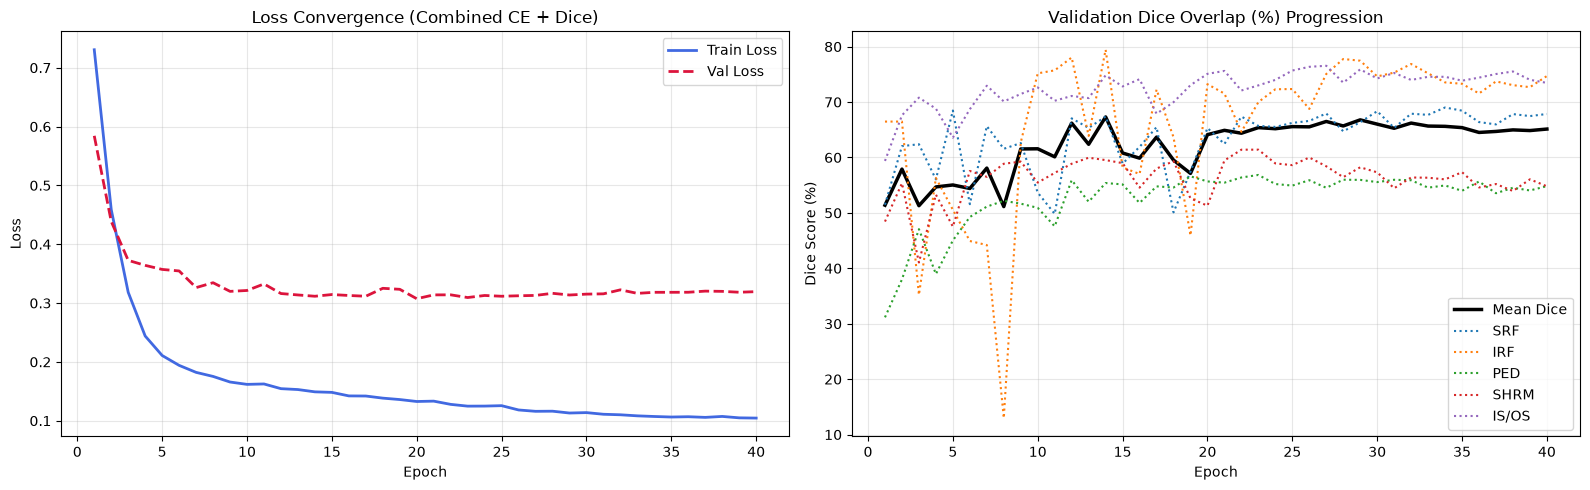

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

if os.path.exists("training_log.csv"):
    df_log = pd.read_csv("training_log.csv")

    fig, axes = plt.subplots(1, 2, figsize=(16, 5))

    # Loss Curves
    axes[0].plot(df_log["epoch"], df_log["train_loss"], label="Train Loss", color="royalblue", lw=2)
    axes[0].plot(df_log["epoch"], df_log["val_loss"], label="Val Loss", color="crimson", lw=2, linestyle="--")
    axes[0].set_title("Loss Convergence (Combined CE + Dice)")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].grid(True, alpha=0.3)
    axes[0].legend()

    # Dice Overlap Progression
    axes[1].plot(df_log["epoch"], df_log["mean_dice"], label="Mean Dice", color="black", lw=2.5)
    axes[1].plot(df_log["epoch"], df_log["SRF_dice"], label="SRF", lw=1.5, linestyle=":")
    axes[1].plot(df_log["epoch"], df_log["IRF_dice"], label="IRF", lw=1.5, linestyle=":")
    axes[1].plot(df_log["epoch"], df_log["PED_dice"], label="PED", lw=1.5, linestyle=":")
    axes[1].plot(df_log["epoch"], df_log["SHRM_dice"], label="SHRM", lw=1.5, linestyle=":")
    axes[1].plot(df_log["epoch"], df_log["IS_OS_dice"], label="IS/OS", lw=1.5, linestyle=":")
    axes[1].set_title("Validation Dice Overlap (%) Progression")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Dice Score (%)")
    axes[1].grid(True, alpha=0.3)
    axes[1].legend()

    plt.tight_layout()
    plt.show()
else:
    print("training_log.csv not found. Execute the training cell first.")

## 6. Baseline Benchmark Evaluation & Visual Predictions

### Overview
This section evaluates the saved optimal model weights (`best_unet_baseline.pth`) on the validation dataset (703 scans)[cite: 2, 5]:
1. **Quantitative Benchmarking:** Calculates validation Dice Similarity Coefficient (DSC) and Intersection over Union (IoU) per lesion class and compares them directly against Table 3 from the AMD-SD paper[cite: 5].
2. **Qualitative Visualization:** Generates a 3-panel comparison figure (Input OCT scan, Ground Truth mask, and Model Prediction) matching Figure 3 from the paper.

In [13]:
import os
import torch
import pandas as pd
from torch.utils.data import DataLoader
from tqdm import tqdm

def evaluate_baseline_replication():
    # Detect device
    device = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
    checkpoint_path = "best_unet_baseline.pth"

    if not os.path.exists(checkpoint_path):
        raise FileNotFoundError(f"Checkpoint not found at '{checkpoint_path}'. Train the model first.")

    val_dataset = AMDDataset("processed_data", split="val")
    val_loader = DataLoader(val_dataset, batch_size=4, shuffle=False, num_workers=0)

    # Load trained model weights
    model = UNet(in_channels=1, num_classes=6, base_channels=32).to(device)
    model.load_state_dict(torch.load(checkpoint_path, map_location=device))
    model.eval()

    val_dice_accum = {"SRF": 0.0, "IRF": 0.0, "PED": 0.0, "SHRM": 0.0, "IS/OS": 0.0}
    val_iou_accum = {"SRF": 0.0, "IRF": 0.0, "PED": 0.0, "SHRM": 0.0, "IS/OS": 0.0}
    total_batches = 0

    with torch.no_grad():
        for images, targets in tqdm(val_loader, desc="Evaluating Validation Set"):
            images = images.to(device)
            targets = targets.to(device, dtype=torch.long)

            logits = model(images)
            preds = torch.argmax(logits, dim=1)

            d_scores, i_scores = calculate_metrics(preds, targets)
            for k in val_dice_accum:
                val_dice_accum[k] += d_scores[k]
                val_iou_accum[k] += i_scores[k]
            total_batches += 1

    # Compute averages
    my_dice = {k: v / total_batches for k, v in val_dice_accum.items()}
    my_iou = {k: v / total_batches for k, v in val_iou_accum.items()}
    my_mean_dice = sum(my_dice.values()) / len(my_dice)
    my_mean_iou = sum(my_iou.values()) / len(my_iou)

    # Reference values from Table 3 in the paper[cite: 5]
    paper_unet_dice = {"SRF": 78.65, "IRF": 78.66, "PED": 79.62, "SHRM": 72.04, "IS/OS": 83.76, "Mean": 78.55}
    paper_unet_iou  = {"SRF": 64.81, "IRF": 64.82, "PED": 66.14, "SHRM": 56.37, "IS/OS": 72.06, "Mean": 64.48}

    report = pd.DataFrame({
        "Lesion Structure": ["SRF", "IRF", "PED", "SHRM", "IS/OS", "Mean Average"],
        "Paper U-Net Dice (%)": [
            paper_unet_dice["SRF"], paper_unet_dice["IRF"], paper_unet_dice["PED"],
            paper_unet_dice["SHRM"], paper_unet_dice["IS/OS"], paper_unet_dice["Mean"]
        ],
        "Replicated Dice (%)": [
            round(my_dice["SRF"], 2), round(my_dice["IRF"], 2), round(my_dice["PED"], 2),
            round(my_dice["SHRM"], 2), round(my_dice["IS/OS"], 2), round(my_mean_dice, 2)
        ],
        "Paper U-Net IoU (%)": [
            paper_unet_iou["SRF"], paper_unet_iou["IRF"], paper_unet_iou["PED"],
            paper_unet_iou["SHRM"], paper_unet_iou["IS/OS"], paper_unet_iou["Mean"]
        ],
        "Replicated IoU (%)": [
            round(my_iou["SRF"], 2), round(my_iou["IRF"], 2), round(my_iou["PED"], 2),
            round(my_iou["SHRM"], 2), round(my_iou["IS/OS"], 2), round(my_mean_iou, 2)
        ]
    })

    print("\n" + "="*80)
    print("BASELINE REPLICATION RESULTS vs. PAPER BENCHMARK (Table 3)[cite: 5]")
    print("="*80)
    print(report.to_string(index=False))
    report.to_csv("replication_benchmark_report.csv", index=False)
    print("\nReport saved to 'replication_benchmark_report.csv'.")
    return report

benchmark_df = evaluate_baseline_replication()

Evaluating Validation Set: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 176/176 [00:43<00:00,  4.01it/s]


BASELINE REPLICATION RESULTS vs. PAPER BENCHMARK (Table 3)[cite: 5]
Lesion Structure  Paper U-Net Dice (%)  Replicated Dice (%)  Paper U-Net IoU (%)  Replicated IoU (%)
             SRF                 78.65                67.40                64.81               60.38
             IRF                 78.66                79.44                64.82               75.38
             PED                 79.62                55.39                66.14               46.39
            SHRM                 72.04                59.53                56.37               51.30
           IS/OS                 83.76                74.83                72.06               64.48
    Mean Average                 78.55                67.32                64.48               59.59

Report saved to 'replication_benchmark_report.csv'.


### 6.1 Qualitative Prediction Visualization
Visualizes validation predictions against ground truth masks across different eyes and retinal pathology severities, matching the visualization protocol of Figure 3 in the paper[cite: 5, 7].

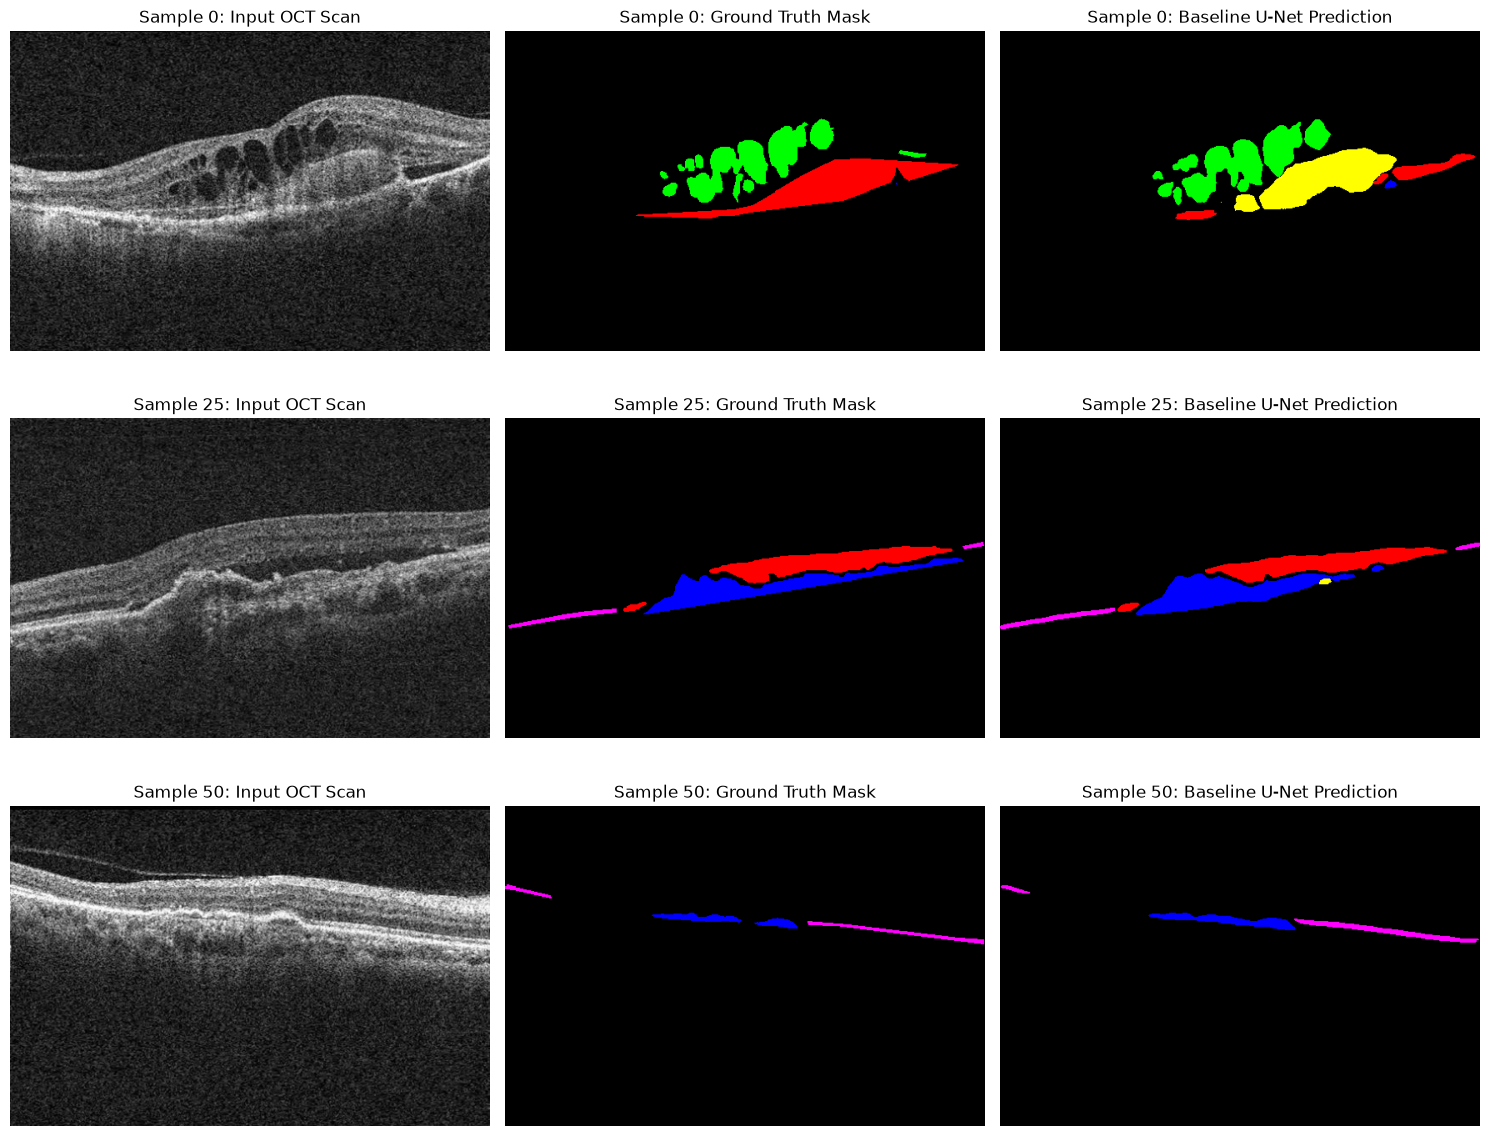

Saved visualization to 'sample_predictions.jpg'.


In [14]:
import matplotlib.pyplot as plt

COLOR_MAP_RGB = {
    0: [0, 0, 0],        # Background (Black)[cite: 5]
    1: [255, 0, 0],      # SRF: Subretinal Fluid (Red)[cite: 5]
    2: [0, 255, 0],      # IRF: Intraretinal Fluid (Green)[cite: 5]
    3: [0, 0, 255],      # PED: Pigment Epithelial Detachment (Blue)[cite: 5]
    4: [255, 255, 0],    # SHRM: Subretinal Hyperreflective Material (Yellow)[cite: 5]
    5: [255, 0, 255]     # IS/OS: Ellipsoid Zone (Pink)[cite: 5]
}

def labels_to_rgb(label_map):
    """Converts a 2D integer class tensor into an RGB visualization mask."""
    h, w = label_map.shape
    rgb_img = np.zeros((h, w, 3), dtype=np.uint8)
    for class_id, color in COLOR_MAP_RGB.items():
        rgb_img[label_map == class_id] = color
    return rgb_img

def plot_validation_predictions(sample_indices=[0, 25, 50]):
    device = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
    val_dataset = AMDDataset("processed_data", split="val")

    model = UNet(in_channels=1, num_classes=6, base_channels=32).to(device)
    model.load_state_dict(torch.load("best_unet_baseline.pth", map_location=device))
    model.eval()

    num_samples = len(sample_indices)
    fig, axes = plt.subplots(num_samples, 3, figsize=(15, 4 * num_samples))

    for row, idx in enumerate(sample_indices):
        img_tensor, mask_tensor = val_dataset[idx]

        with torch.no_grad():
            input_batch = img_tensor.unsqueeze(0).to(device)
            logits = model(input_batch)
            pred_mask = torch.argmax(logits, dim=1).squeeze(0).cpu().numpy()

        input_img = (img_tensor.squeeze(0).numpy() * 255).astype(np.uint8)
        gt_rgb = labels_to_rgb(mask_tensor.numpy())
        pred_rgb = labels_to_rgb(pred_mask)

        # Plot Input OCT Scan
        axes[row, 0].imshow(input_img, cmap="gray")
        axes[row, 0].set_title(f"Sample {idx}: Input OCT Scan")
        axes[row, 0].axis("off")

        # Plot Ground Truth
        axes[row, 1].imshow(gt_rgb)
        axes[row, 1].set_title(f"Sample {idx}: Ground Truth Mask")
        axes[row, 1].axis("off")

        # Plot Baseline U-Net Prediction
        axes[row, 2].imshow(pred_rgb)
        axes[row, 2].set_title(f"Sample {idx}: Baseline U-Net Prediction")
        axes[row, 2].axis("off")

    plt.tight_layout()
    plt.savefig("sample_predictions.jpg", dpi=300)
    plt.show()
    print("Saved visualization to 'sample_predictions.jpg'.")

plot_validation_predictions(sample_indices=[0, 25, 50])